In [1]:
from google.colab import files
import pandas as pd

# Upload files manually from your explorer
uploaded = files.upload()


Saving fear_greed_index.csv to fear_greed_index.csv
Saving historical_data.csv to historical_data.csv


In [2]:
import pandas as pd

trades = pd.read_csv("historical_data.csv")
sentiment = pd.read_csv("fear_greed_index.csv")

In [6]:
trades['Date'] = pd.to_datetime(trades['Timestamp IST'], format='%d-%m-%Y %H:%M').dt.date

sentiment['Date'] = pd.to_datetime(sentiment['date']).dt.date

In [7]:
merged = pd.merge(
    trades,
    sentiment,
    on='Date',
    how='left'
)

In [8]:
merged.info()
merged.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 211224 entries, 0 to 211223
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Account           211224 non-null  object 
 1   Coin              211224 non-null  object 
 2   Execution Price   211224 non-null  float64
 3   Size Tokens       211224 non-null  float64
 4   Size USD          211224 non-null  float64
 5   Side              211224 non-null  object 
 6   Timestamp IST     211224 non-null  object 
 7   Start Position    211224 non-null  float64
 8   Direction         211224 non-null  object 
 9   Closed PnL        211224 non-null  float64
 10  Transaction Hash  211224 non-null  object 
 11  Order ID          211224 non-null  int64  
 12  Crossed           211224 non-null  bool   
 13  Fee               211224 non-null  float64
 14  Trade ID          211224 non-null  float64
 15  Timestamp         211224 non-null  float64
 16  Date              21

,Execution Price,Size Tokens,Size USD,Start Position,Closed PnL,Order ID,Fee,Trade ID,Timestamp,timestamp,value
count,211224.000000,2.112240e+05,2.112240e+05,2.112240e+05,211224.000000,2.112240e+05,211224.000000,2.112240e+05,2.112240e+05,2.112180e+05,211218.000000
mean,11414.723350,4.623365e+03,5.639451e+03,-2.994625e+04,48.749001,6.965388e+10,1.163967,5.628549e+14,1.737744e+12,1.738301e+09,51.649656
std,29447.654868,1.042729e+05,3.657514e+04,6.738074e+05,919.164828,1.835753e+10,6.758854,3.257565e+14,8.689920e+09,8.029302e+06,21.012784
min,0.000005,8.740000e-07,0.000000e+00,-1.433463e+07,-117990.104100,1.732711e+08,-1.175712,0.000000e+00,1.680000e+12,1.682919e+09,10.000000
25%,4.854700,2.940000e+00,1.937900e+02,-3.762311e+02,0.000000,5.983853e+10,0.016121,2.810000e+14,1.740000e+12,1.735623e+09,33.000000
50%,18.280000,3.200000e+01,5.970450e+02,8.472793e+01,0.000000,7.442939e+10,0.089578,5.620000e+14,1.740000e+12,1.740375e+09,49.000000
75%,101.580000,1.879025e+02,2.058960e+03,9.337278e+03,5.792797,8.335543e+10,0.393811,8.460000e+14,1.740000e+12,1.743572e+09,72.000000
max,109004.000000,1.582244e+07,3.921431e+06,3.050948e+07,135329.090100,9.014923e+10,837.471593,1.130000e+15,1.750000e+12,1.746077e+09,94.000000


In [18]:
merged.groupby('classification')['Closed PnL'].mean()

,Closed PnL
classification,
Extreme Fear,34.537862
Extreme Greed,67.892861
Fear,54.290400
Greed,42.743559
Neutral,34.307718


In [19]:
merged.groupby('classification')['Size Tokens'].mean()

,Size Tokens
classification,
Extreme Fear,1675.893319
Extreme Greed,8832.415746
Fear,2992.641845
Greed,4715.327756
Neutral,4383.368714


In [29]:
pd.pivot_table(
    merged,
    values='Closed PnL',
    index='classification',
    columns='Side',
    aggfunc='mean'
)

Side,BUY,SELL
classification,,
Extreme Fear,34.114627,34.980106
Extreme Greed,10.498927,114.584643
Fear,63.927104,45.049641
Greed,25.002302,59.691091
Neutral,29.227429,39.456408


In [31]:
merged.groupby('Account')['Closed PnL'].sum()

,Closed PnL
Account,
0x083384f897ee0f19899168e3b1bec365f52a9012,1.600230e+06
0x23e7a7f8d14b550961925fbfdaa92f5d195ba5bd,4.788532e+04
0x271b280974205ca63b716753467d5a371de622ab,-7.043619e+04
0x28736f43f1e871e6aa8b1148d38d4994275d72c4,1.324648e+05
0x2c229d22b100a7beb69122eed721cee9b24011dd,1.686580e+05
0x3998f134d6aaa2b6a5f723806d00fd2bbbbce891,-3.120360e+04
0x39cef799f8b69da1995852eea189df24eb5cae3c,1.445692e+04
0x3f9a0aadc7f04a7c9d75dc1b5a6ddd6e36486cf6,5.349625e+04
0x420ab45e0bd8863569a5efbb9c05d91f40624641,1.995056e+05


In [32]:
merged['win'] = merged['Closed PnL'] > 0

In [33]:
merged.groupby('classification')['win'].mean()

,win
classification,
Extreme Fear,0.370607
Extreme Greed,0.464943
Fear,0.420768
Greed,0.384828
Neutral,0.396991


In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

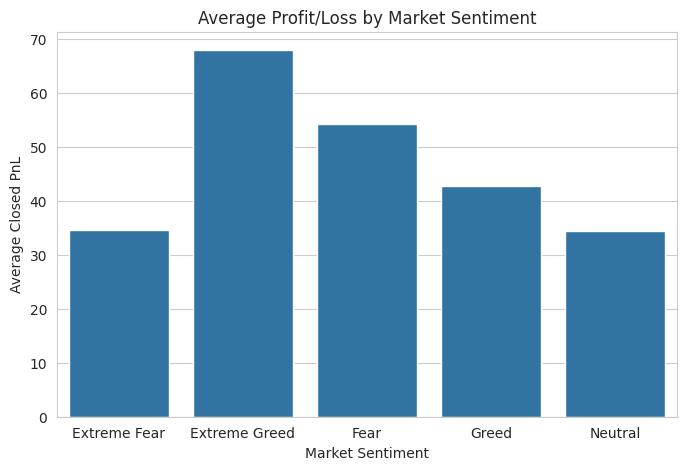

In [35]:
plt.figure(figsize=(8,5))

avg_pnl = merged.groupby('classification')['Closed PnL'].mean().reset_index()

sns.barplot(data=avg_pnl,
            x='classification',
            y='Closed PnL')

plt.title('Average Profit/Loss by Market Sentiment')
plt.xlabel('Market Sentiment')
plt.ylabel('Average Closed PnL')
plt.show()

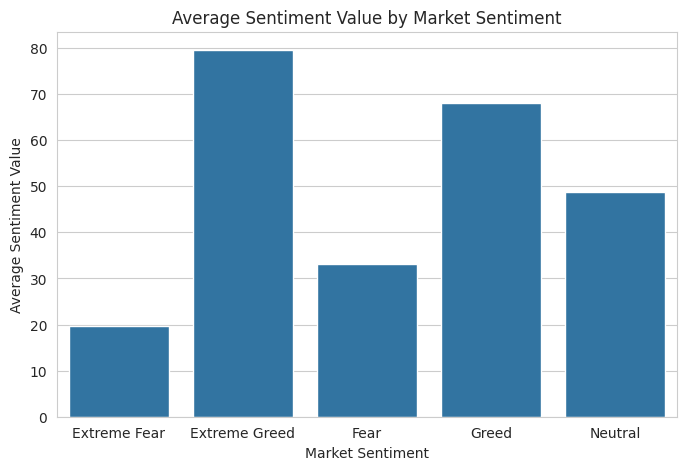

In [36]:
plt.figure(figsize=(8,5))

avg_lev = merged.groupby('classification')['value'].mean().reset_index()

sns.barplot(data=avg_lev,
            x='classification',
            y='value')

plt.title('Average Sentiment Value by Market Sentiment')
plt.xlabel('Market Sentiment')
plt.ylabel('Average Sentiment Value')
plt.show()

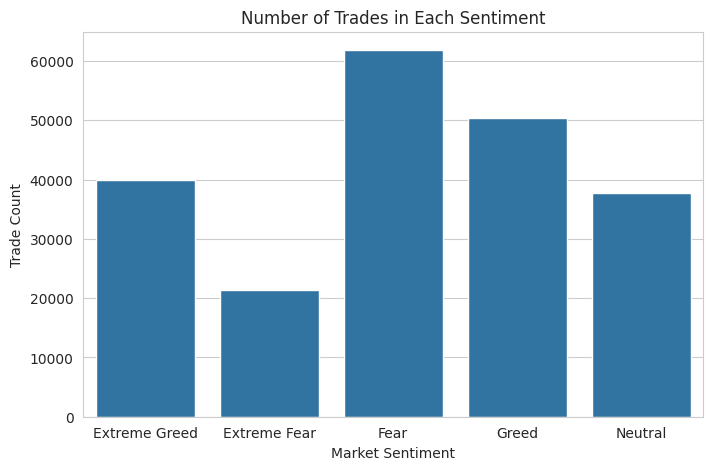

In [37]:
plt.figure(figsize=(8,5))

sns.countplot(data=merged,
              x='classification')

plt.title('Number of Trades in Each Sentiment')
plt.xlabel('Market Sentiment')
plt.ylabel('Trade Count')
plt.show()

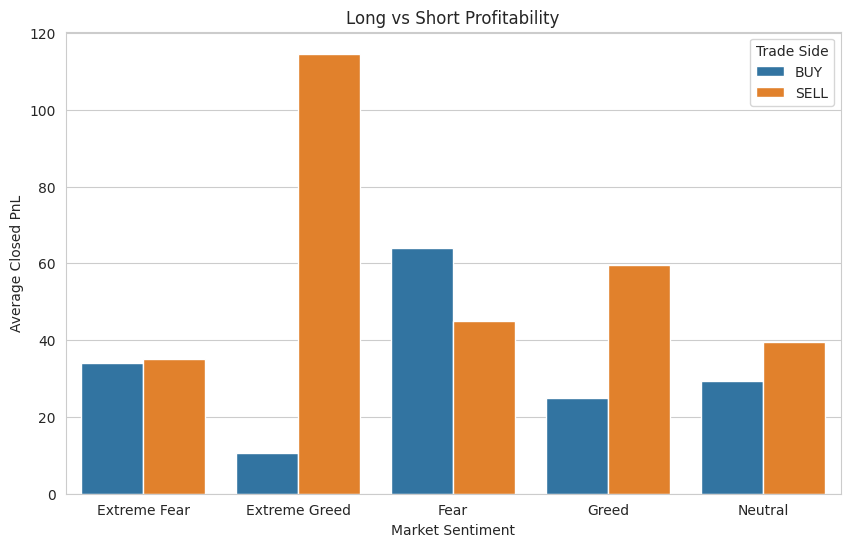

In [38]:
plt.figure(figsize=(10,6))

side_pnl = merged.groupby(
    ['classification', 'Side']
)['Closed PnL'].mean().reset_index()

sns.barplot(data=side_pnl,
            x='classification',
            y='Closed PnL',
            hue='Side')

plt.title('Long vs Short Profitability')
plt.xlabel('Market Sentiment')
plt.ylabel('Average Closed PnL')
plt.legend(title='Trade Side')
plt.show()

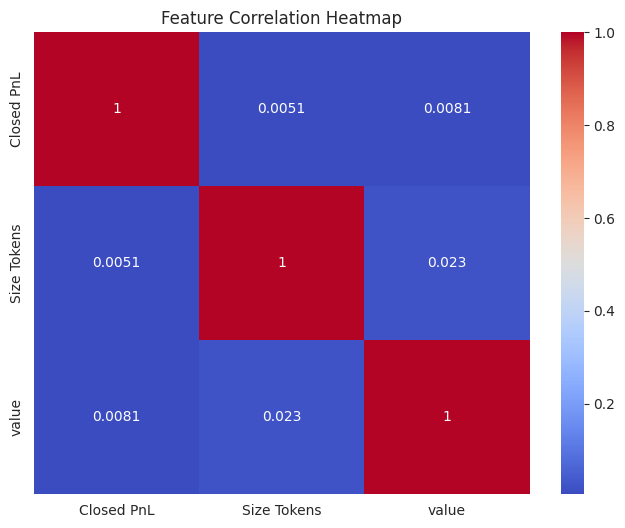

In [39]:
plt.figure(figsize=(8,6))

corr = merged[['Closed PnL',
               'Size Tokens',
               'value']].corr()

sns.heatmap(corr,
            annot=True,
            cmap='coolwarm')

plt.title('Feature Correlation Heatmap')
plt.show()

In [40]:
avg_lev = merged.groupby('classification')['value'].mean()

KeyError: 'Column not found: leverage'

In [41]:
print(merged.columns.tolist())

['Account', 'Coin', 'Execution Price', 'Size Tokens', 'Size USD', 'Side', 'Timestamp IST', 'Start Position', 'Direction', 'Closed PnL', 'Transaction Hash', 'Order ID', 'Crossed', 'Fee', 'Trade ID', 'Timestamp', 'Date', 'timestamp', 'value', 'classification', 'date', 'win']


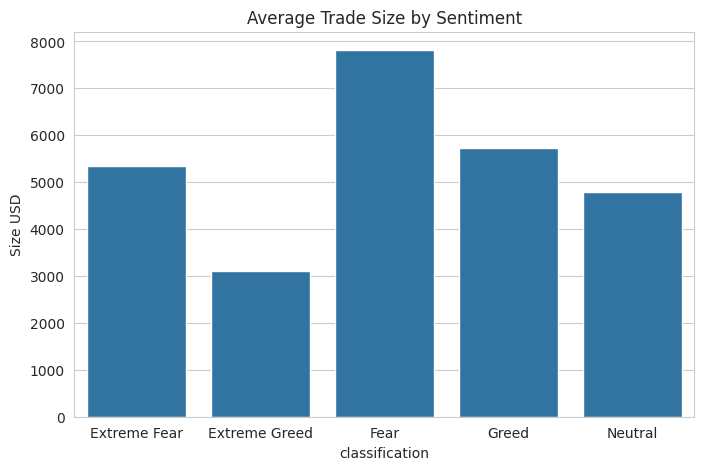

In [42]:
trade_size = merged.groupby('classification')['Size USD'].mean().reset_index()

plt.figure(figsize=(8,5))
sns.barplot(data=trade_size,
            x='classification',
            y='Size USD')

plt.title('Average Trade Size by Sentiment')
plt.show()

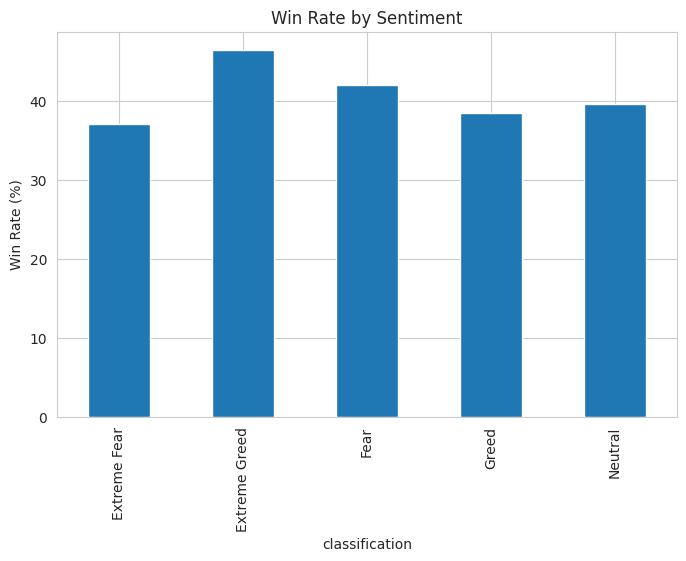

In [43]:
win_rate = merged.groupby('classification')['win'].mean()*100

plt.figure(figsize=(8,5))
win_rate.plot(kind='bar')

plt.title('Win Rate by Sentiment')
plt.ylabel('Win Rate (%)')
plt.show()

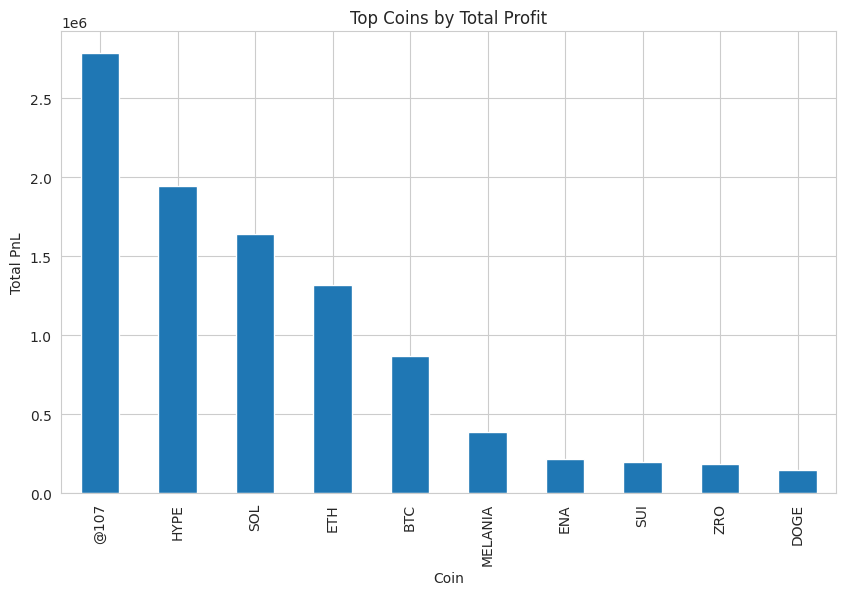

In [44]:
top_coins = merged.groupby('Coin')['Closed PnL'].sum() \
                  .sort_values(ascending=False) \
                  .head(10)

plt.figure(figsize=(10,6))
top_coins.plot(kind='bar')

plt.title('Top Coins by Total Profit')
plt.ylabel('Total PnL')
plt.show()

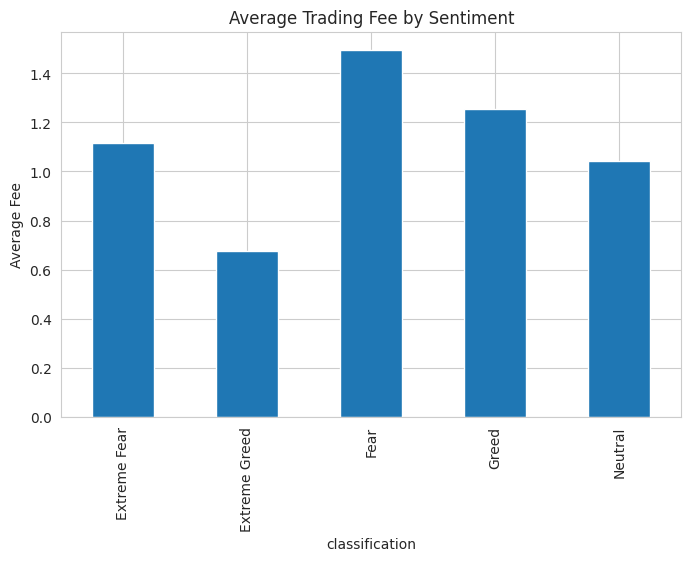

In [45]:
fee_analysis = merged.groupby('classification')['Fee'].mean()

plt.figure(figsize=(8,5))
fee_analysis.plot(kind='bar')

plt.title('Average Trading Fee by Sentiment')
plt.ylabel('Average Fee')
plt.show()

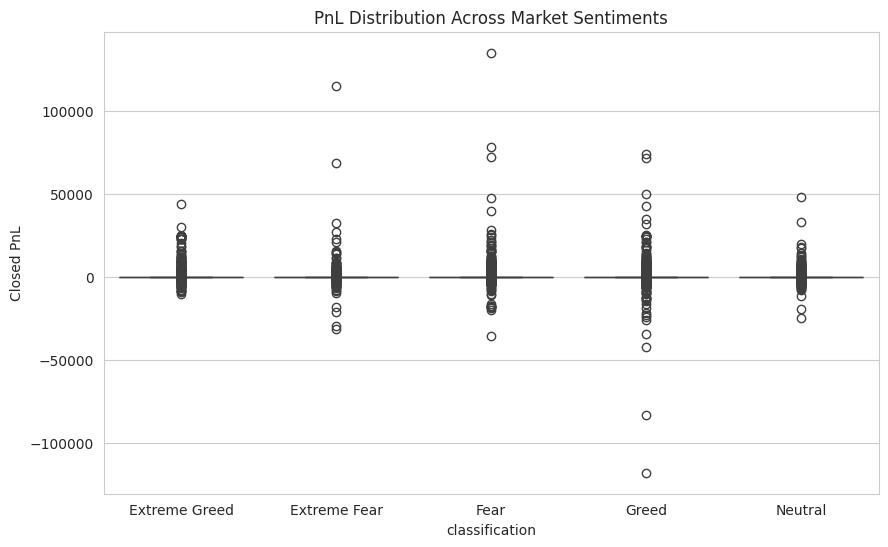

In [46]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=merged,
    x='classification',
    y='Closed PnL'
)

plt.title('PnL Distribution Across Market Sentiments')
plt.show()